# 实验五：使用 PyTorch 训练 MNIST 手写数字分类模型 · 参考答案

在实验四中，我们基于 `numpy` 实现了手动的前向传播、BP 和 梯度下降。现在使用 PyTorch 实现 MNIST 图像分类。框架帮助我们自动计算梯度，让我们将更多精力放在**数据、训练流程、验证与实验结论**。这次将处理图像数据集，完成一个完整的分类任务。

这里我们用**全连接模型**而不是 CNN 来处理 MNIST 的二维图像，主要是为了和上次的手动 Numpy 进行衔接，避免在引入 pytorch 的同时给同学们带来过多的知识点，难度上会更平滑一点。

实验主线：认识数据 → 建立分类模型 → 检查一次更新 → 小批量训练 → 验证选模 → 最终测试与错误分析。

**Q1–Q7 必做；Q8 为选做学习率对照。** Q1 是教师演示。先写预测，再补全代码，最后用输出解释结果。


本参考版按最新学生版组织，包含完整代码、文字解释和实际运行结果；Q8 也已开启。不同设备上的耗时和指标可能略有差异。


## 0 · 文件、环境和实验约定

本实验使用 CPU 即可完成，不要求配置 GPU。

实验设计与内容参考 [d2l相关章节](https://zh.d2l.ai/chapter_linear-networks/softmax-regression-scratch.html)。但不需要安装 `d2l` 的包。

第一次联网运行时，将下一单元的 `DOWNLOAD` 改为 `True`；数据缓存就绪后改回 `False`。离线时复制教师已准备的 `data/MNIST/raw/` 目录；这里的下载开关与 pip 软件源无关。

| 设置       | 本版约定                                                                |
| ---------- | ----------------------------------------------------------------------- |
| 数据划分   | 官方训练集固定拆成 50,000 训练、10,000 验证；官方测试集 10,000 最终使用 |
| 输入       | float32，单通道 28×28，像素范围 [0,1]；无额外标准化或增强               |
| 标签       | long，类别下标 0–9，形状 (B,)                                           |
| 主模型     | Flatten → Linear(784,128) → ReLU → Linear(128,10)                       |
| 输出与损失 | logits，不加 softmax；CrossEntropyLoss 默认 mean                        |
| 优化       | SGD，无动量；lr=0.1，batch_size=128，epochs=5                           |
| 随机设置   | 划分、初始化、批次顺序分别固定；CPU 为默认验证环境                      |
| 选模规则   | 验证准确率优先，相同准确率时验证损失较小优先，完全相同取较早轮次        |

先预测：框架计算了梯度，是否意味着数据、损失和训练流程就一定正确？


**参考回答：** 自动求导负责根据计算图求梯度；图像与标签是否配对、网络结构是否合适、损失是否用对、模型是否在未见数据上有效，仍需我们检查。本实验使用 CPU 即可，不要求配置 GPU。


In [1]:
import math
import os
from pathlib import Path
import sys
import time

import numpy as np
import platform
import torch
from torch import nn
from torch.utils.data import TensorDataset, Subset
import torchvision

from lab_utils import (
    seed_everything,
    data_root,
    load_train_val,
    load_test,
    make_loader,
    snapshot,
    plot_samples,
    plot_history,
    collect_errors,
)

assert Path("lab_utils.py").exists(), "请在实验五目录启动 notebook"

SEED, SPLIT_SEED, ORDER_SEED = 42, 42, 2026
BATCH_SIZE, EPOCHS, LR = 128, 5, 0.1
DOWNLOAD = False  # 第一次联网下载时改为 True，缓存就绪后改回 False。
DEVICE = torch.device("cpu")  # 已有 CUDA 环境可自行改为 torch.device("cuda")。
# 小模型使用过多 CPU 线程可能更慢；限制线程数便于普通电脑复现。
torch.set_num_threads(min(4, os.cpu_count() or 1))
seed_everything(SEED)
print("Python:", sys.version.split()[0], sys.executable)
print("PyTorch:", torch.__version__, "torchvision:", torchvision.__version__)
print(
    "device:",
    DEVICE,
    "threads:",
    torch.get_num_threads(),
    "machine:",
    platform.machine(),
)
print("data root:", data_root().resolve())
print(
    {
        "seed": SEED,
        "split_seed": SPLIT_SEED,
        "order_seed": ORDER_SEED,
        "batch_size": BATCH_SIZE,
        "lr": LR,
        "epochs": EPOCHS,
    }
)


Python: 3.9.6 /private/tmp/ustc-lab5-venv/bin/python
PyTorch: 2.8.0 torchvision: 0.23.0
device: cpu threads: 4 machine: arm64
data root: /private/tmp/ustc-lab5-data
{'seed': 42, 'split_seed': 42, 'order_seed': 2026, 'batch_size': 128, 'lr': 0.1, 'epochs': 5}


## Q1 · 从手写 BP 到自动求导（必做，教师演示）

在实验四中，我们设定的模型为：$Z_1=XW_1+b_1$，$A_1=\tanh(Z_1)$，$\hat y=A_1W_2+b_2$，$L=\mathrm{mean}((\hat y-y)^2)$。

下面是一个已经完成的代码块，前半部分为上次实验中用 `numpy` 实现的内容，后半部分则是用 `torch` 实现的内容。请先阅读代码，了解并感受 `torch` 在这个任务上的简洁之处，以及每层之间的信息是怎么传递的。

> 尽量保证能够独立说出每一行代码在做什么事，再往后推进。相关注释已经在代码中补充。


In [2]:
# --- Numpy 实现的 BP 算法 ---
rng = np.random.default_rng(7)
x_np = np.array([[-0.7], [0.2], [0.9]], dtype=np.float64)
y_np = np.sin(x_np)
p_np = {
    "W1": rng.normal(size=(1, 3)),
    "b1": np.zeros((1, 3)),
    "W2": rng.normal(scale=1 / np.sqrt(3), size=(3, 1)),
    "b2": np.zeros((1, 1)),
}
a = np.tanh(x_np @ p_np["W1"] + p_np["b1"])
yhat = a @ p_np["W2"] + p_np["b2"]
dy = 2 * (yhat - y_np) / len(x_np)
dz = (dy @ p_np["W2"].T) * (1 - a**2)
manual = {
    "W1": x_np.T @ dz,
    "b1": dz.sum(0, keepdims=True),
    "W2": a.T @ dy,
    "b2": dy.sum(0, keepdims=True),
}

# --- torch 实现的 BP 算法 ---
# 这里的参数用字典的形式存储，key 和 p_np 中的索引相同，但存储的内容变成了 Tensor，即张量。
params = {
    k: nn.Parameter(torch.tensor(v, dtype=torch.float64)) for k, v in p_np.items()
}
# 值得说明的是，这里的 tensor 初始化传入的是 numpy 的 array，
# 初始化的过程与方式已经打包进了工具包，这里是直接将 NumPy 数组转成了同形状的 Tensor。
x_demo, y_demo = torch.tensor(x_np), torch.tensor(y_np)


def demo_loss():
    """使用 torch 计算得到的损失。"""
    Z1 = x_demo @ params["W1"] + params["b1"]
    A1 = torch.tanh(Z1)
    y_pred = A1 @ params["W2"] + params["b2"]
    return ((y_pred - y_demo) ** 2).mean()


before = {k: p.detach().clone() for k, p in params.items()}

# 初始化 torch 的优化器，并设置好学习率 lr
optimizer_demo = torch.optim.SGD(params.values(), lr=0.001)
optimizer_demo.zero_grad(set_to_none=True)  # 清除旧梯度（将 .grad 设为 None）

demo_loss().backward()
first_grad = {k: p.grad.clone() for k, p in params.items()}
for k, p in params.items():
    np.testing.assert_allclose(p.grad.numpy(), manual[k], rtol=1e-10, atol=1e-12)
    assert torch.equal(p, before[k])
    print(k, "max gradient error =", np.max(np.abs(p.grad.numpy() - manual[k])))


W1 max gradient error = 5.551115123125783e-17
b1 max gradient error = 5.551115123125783e-17
W2 max gradient error = 1.0842021724855044e-19
b2 max gradient error = 5.551115123125783e-17


**参考解释：** NumPy 部分用链式法则逐项写出四组参数的梯度；PyTorch 部分记录前向计算，再由 `demo_loss().backward()` 求出这些梯度。两边使用相同参数值、float64 和同一损失，才可直接比较。

`nn.Parameter` 表示需要学习的参数；`p.grad` 保存求出的梯度。`detach().clone()` 保存一份不参与求导的独立参数副本，用来检查求梯度前后参数是否变化。

本单元只调用了 `backward()`，没有调用 `optimizer_demo.step()`，因此参数保持不变。`zero_grad(set_to_none=True)` 清除旧梯度，避免后续反向传播与旧值累加。PyTorch 帮助求导，但矩阵形状和前向计算仍需正确。


## Q2 · 数据、标签与小批量（必做）

教师提供固定划分和加载工具。此时只使用官方训练数据；测试集到 Q7 才加载和评估。

查看样本并补全形状表，说明每个维度的含义。为什么标签是整数类别下标，而不是待拟合的连续数值？

| 量                | 形状 | dtype | 含义 |
| ----------------- | ---- | ----- | ---- |
| 一个 batch 的图像 | `(B,1,28,28)` | `float32` | B 张单通道图像 |
| 一个 batch 的标签 | `(B,)` | `long` | 每张图像对应的整数类别 |
| 展平后图像 | `(B,784)` | `float32` | 每张图像的 784 个像素 |
| 模型输出 | `(B,10)` | `float32` | 每张图像的十个类别分数 |

**问题**：对于这里的图像，我们将其转换成了什么样的数据？

**参考回答**：每张灰度图转换为一个 `(1,28,28)` 的 float32 张量，像素值从整数 0–255 缩放到 [0,1]。DataLoader 再将多张图像组成 `(B,1,28,28)` 的 batch。标签保留整数类别下标，不能把类别编号之间的数值距离当作本任务的误差。训练数据用于更新参数，验证数据用于选择模型和轮次，测试数据留到方案确定后评估。


images: torch.Size([128, 1, 28, 28]) torch.float32 labels: torch.Size([128]) torch.int64
batches/epoch: 391 last batch: 80


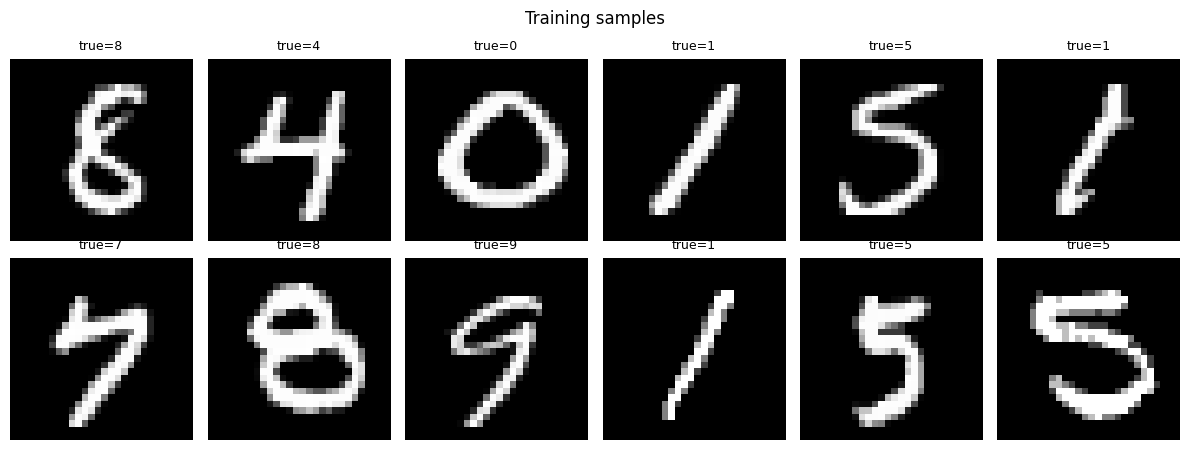

In [3]:
# 这里的数据集下载已经打包成 `load_train_val` 函数，只需要自行传参即可
train_set, val_set = load_train_val(download=DOWNLOAD, split_seed=SPLIT_SEED)
assert len(train_set) == 50000 and len(val_set) == 10000
assert not set(train_set.indices).intersection(val_set.indices)
assert len(set(train_set.indices) | set(val_set.indices)) == 60000

val_loader = make_loader(val_set, BATCH_SIZE)
train_eval_loader = make_loader(train_set, BATCH_SIZE)

# 探索样本使用独立 loader，不消耗正式训练的随机 generator。
x_batch, y_batch = next(
    iter(make_loader(train_set, BATCH_SIZE, shuffle=True, seed=ORDER_SEED))
)
assert x_batch.shape == (BATCH_SIZE, 1, 28, 28)
assert x_batch.dtype == torch.float32 and y_batch.dtype == torch.long
assert y_batch.shape == (BATCH_SIZE,) and 0 <= y_batch.min() <= y_batch.max() <= 9
assert 0 <= x_batch.min() <= x_batch.max() <= 1

print("images:", x_batch.shape, x_batch.dtype, "labels:", y_batch.shape, y_batch.dtype)
print(
    "batches/epoch:",
    math.ceil(len(train_set) / BATCH_SIZE),
    "last batch:",
    len(train_set) % BATCH_SIZE,
)


# 确认我们下载好的数据集
_ = plot_samples(x_batch[:12], y_batch[:12], title="Training samples")


## Q3 · 建立分类模型

实现函数 `build_model(kind="mlp", seed=42)`，并返回位于 `DEVICE` 的网络。保留给定的种子设置。

`DEVICE` 指定计算设备（CPU/GPU）。本实验使用 CPU；`.to(DEVICE)` 将模型参数或数据移动到指定设备。参与同一次计算的模型和数据需要位于同一设备。

下面我们将设计两种网络：

- `mlp`：Flatten → Linear(784,128) → ReLU → Linear(128,10)。
- `linear`：Flatten → Linear(784,10)，供 Q6 对照。
- 未知 kind 应抛出 ValueError。

输出十个 logits（未经归一化的分数），不添加 softmax。


In [4]:
def build_model(kind="mlp", seed=42):
    seed_everything(seed)
    # Sequential 将网络层按顺序连接，上一层的输出作为下一层的输入。
    if kind == "mlp":
        model = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )
    elif kind == "linear":
        model = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))
    else:
        raise ValueError("kind 必须为 mlp 或 linear")
    # 模型输出 logits，不在这里添加 softmax。
    return model.to(DEVICE)


In [5]:
model = build_model("mlp", SEED)
scores = model(x_batch.to(DEVICE))
assert scores.shape == (len(y_batch), 10)
assert torch.isfinite(scores).all()
assert sum(p.numel() for p in model.parameters()) == 101770
assert sum(p.numel() for p in build_model("linear", SEED).parameters()) == 7850
print(model)
print("MLP parameters:", sum(p.numel() for p in model.parameters()))
print("logits of first sample:", scores[0].detach().cpu())


Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=10, bias=True)
)
MLP parameters: 101770
logits of first sample: tensor([ 0.0184, -0.0672,  0.0072, -0.0471, -0.1107,  0.0620,  0.0245, -0.0831,
         0.1975, -0.0176])


**参考解释：** `nn.Flatten()` 保留 batch 维，将每张 `(1,28,28)` 图像展平为 784 个像素。隐藏层产生 128 个特征，输出层为十个类别各给一个分数，因此输出为 `(B,10)`。

MLP 含 ReLU，是非线性全连接网络；linear 分支只有一个仿射层。两者参数量分别为 101,770 与 7,850。PyTorch 的 Linear 权重排列为 `(输出维度,输入维度)`，前向计算为 $XW^T+b$，与 Q1 中直接保存 $W$ 的方式不同。


## Q4 · 分类损失与一次参数更新（必做）

设第 i 个样本的类别分数为 $z_{i,k}$，真实类别为 $y_i$，交叉熵为

$$
L=-\frac1B\sum_i\log\frac{\exp(z_{i,y_i})}{\sum_{k=0}^9\exp(z_{i,k})}.
$$

`nn.CrossEntropyLoss` 是损失类，使用 `nn.CrossEntropyLoss()` 创建损失函数对象。该对象接收 logits 和整数类别标签，稳定地组合所需运算；不要先对 logits 做 softmax 再传入。

先运行下面的小例子：两个结果的预测类别相同，准确率相同，损失是否相同？为什么不能用 argmax 后的准确率直接反向传播？


In [6]:
criterion = nn.CrossEntropyLoss()
target_demo = torch.tensor([3])
for margin in [0.2, 5.0]:
    z = torch.zeros(1, 10)
    z[0, 3] = margin
    print(
        f"margin={margin}, predicted={z.argmax(1).item()}, "
        f"p(true)={z.softmax(1)[0, 3].item():.4f}, CE={criterion(z, target_demo).item():.4f}"
    )


margin=0.2, predicted=3, p(true)=0.1195, CE=2.1245
margin=5.0, predicted=3, p(true)=0.9428, CE=0.0589


**参考回答：** 两次预测都是类别 3，准确率都为 100%，但正确类别的概率约为 0.1195 和 0.9428，交叉熵约为 2.1245 和 0.0589。交叉熵还能区分“预测相同但分数不同”的输出。

`argmax` 是离散选择，输出的类别下标不能提供训练所需的有效梯度。因此使用交叉熵训练，用准确率评价。`nn.CrossEntropyLoss` 是类，`criterion = nn.CrossEntropyLoss()` 创建可调用的损失函数对象；输入直接使用 logits 与整数标签。


下面补全 `train_step`，返回本批**更新前**的损失总和、预测正确数和样本数。

固定接口为 `{"loss_sum": float, "correct": int, "n": int}`。损失函数采用默认 mean，因此乘以本批真实样本数得到 loss_sum。不要把带计算图的 loss 保存在训练历史中。

顺序：清除旧梯度 → 前向 → 损失 → backward → step。图像与标签均需移动到同一 device。


In [7]:
def train_step(model, x, y, optimizer, criterion, device):
    """完成一个 batch 的参数更新，返回更新前的统计量。"""
    model.train()
    # 模型与参与计算的数据需要位于同一设备。
    x, y = x.to(device), y.to(device)
    # 清除优化器所管理参数的旧梯度，避免与当前 batch 的梯度累加。
    optimizer.zero_grad(set_to_none=True)
    scores = model(x)
    loss = criterion(scores, y)
    if not torch.isfinite(loss):
        raise FloatingPointError("非有限损失，请检查数据和学习率")
    # backward 计算梯度；step 才会根据梯度更新参数。
    loss.backward()
    for parameter in model.parameters():
        if parameter.grad is not None and not torch.isfinite(parameter.grad).all():
            raise FloatingPointError("非有限梯度，尚未执行本次更新")
    optimizer.step()
    # scores 与 loss 来自更新前的前向结果。item() 取出普通数值，不保存计算图。
    return {
        "loss_sum": loss.item() * len(y),
        "correct": (scores.argmax(dim=1) == y).sum().item(),
        "n": len(y),
    }


In [8]:
# 用新模型做一次检查，之后正式训练再重新初始化。
step_model = build_model("mlp", SEED)
step_optimizer = torch.optim.SGD(step_model.parameters(), lr=LR)
params_before = snapshot(step_model)
step_metrics = train_step(
    step_model, x_batch, y_batch, step_optimizer, criterion, DEVICE
)
assert step_metrics["n"] == len(y_batch)
assert math.isfinite(step_metrics["loss_sum"])
assert 0 <= step_metrics["correct"] <= step_metrics["n"]
assert any(
    not torch.equal(params_before[k], v.cpu())
    for k, v in step_model.state_dict().items()
)
assert all(torch.isfinite(p).all() for p in step_model.parameters())
print("single batch before-update metrics:", step_metrics)
# 训练完后的同一批损失仅作观察；任意学习率下一步都下降不是必须满足的数学保证。
with torch.no_grad():
    print(
        "same-batch loss after update:",
        criterion(step_model(x_batch.to(DEVICE)), y_batch.to(DEVICE)).item(),
    )


single batch before-update metrics: {'loss_sum': 293.8939208984375, 'correct': 13, 'n': 128}
same-batch loss after update: 2.268289089202881


**参考解释：** `model.train()` 设置训练模式；`zero_grad` 清除旧梯度；前向和损失定义优化目标；`backward` 求梯度；`step` 更新参数。这些步骤分别对应实验四的前向、损失、BP 和梯度下降。

字典中的损失和正确数来自更新前的同一次前向。mean 损失乘以本批样本数得到损失总和，便于跨批汇总。更新后是否下降还与学习率有关，不能将“一步下降”当作梯度完全正确的证明。


## Q5 · 从一批到完整训练（必做）

实现 `evaluate` 和 `train_epoch`，接口均返回 `{"loss": float, "accuracy": float, "n": int}`。

- `evaluate`：eval 模式和 no_grad 上下文；不更新模型、不清理或改写已有梯度。
- `train_epoch`：遍历 loader，调用 Q4 的 train_step 并汇总；每个 batch 更新一次。
- 两者均按真实样本数加权：`sum(batch_mean_loss * batch_n) / total_n`，准确率为总正确数／总样本数。空 loader 应抛出 ValueError。

提示：

- `model.eval()` 设置 Dropout/BatchNorm 等模块的行为；
- `no_grad()` 关闭梯度记录。当前网络没有这些模块，仍应区分二者。

先用不相同大小 batch 的已知分数检查汇总，再做小样本拟合，最后进入完整训练。


In [9]:
def evaluate(model, loader, criterion, device) -> dict:
    """评估固定模型在整个 loader 上的平均损失与准确率。

    Args:
        model: 需要评估的模型。
        loader: 数据加载器。
        criterion: 损失函数，采用默认 mean 归约。
        device: 用于计算的设备。

    Returns:
        dict: loss 为每个样本的平均损失，accuracy 为正确比例，n 为样本数。
    """
    model.eval()
    loss_sum, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            scores = model(x)
            loss = criterion(scores, y)
            if not torch.isfinite(loss):
                raise FloatingPointError("评估存在非有限损失")
            # 每批平均损失乘本批样本数，避免末尾小批次获得过高权重。
            loss_sum += loss.item() * len(y)
            correct += (scores.argmax(dim=1) == y).sum().item()
            n += len(y)
    if n == 0:
        raise ValueError("不能评估空数据集")
    return {"loss": loss_sum / n, "accuracy": correct / n, "n": n}


def train_epoch(model, loader, optimizer, criterion, device) -> dict:
    """遍历训练集，完成一个 epoch 的训练。

    Args:
        model: 需要训练的模型。
        loader: 训练数据加载器。
        optimizer: 优化器。
        criterion: 损失函数。
        device: 用于计算的设备。

    Returns:
        dict: 本轮训练过程中的平均 loss、accuracy 与样本数 n。
    """
    loss_sum, correct, n = 0.0, 0, 0
    for x, y in loader:
        batch = train_step(model, x, y, optimizer, criterion, device)
        loss_sum += batch["loss_sum"]
        correct += batch["correct"]
        n += batch["n"]
    if n == 0:
        raise ValueError("不能训练空数据集")
    return {"loss": loss_sum / n, "accuracy": correct / n, "n": n}


下面用五个已知分数，检查损失和准确率是否汇总正确。


In [10]:
known_scores = torch.tensor(
    [[5.0, 0.0], [0.0, 5.0], [5.0, 0.0], [0.0, 5.0], [0.0, 5.0]]
)
known_y = torch.tensor([0, 1, 0, 1, 0])  # 最后一张故意错分且损失很大。
known_loader = make_loader(TensorDataset(known_scores, known_y), batch_size=2)
identity = nn.Identity().to(DEVICE)
metrics = evaluate(identity, known_loader, criterion, DEVICE)
expected_loss = criterion(known_scores, known_y).item()
assert abs(metrics["loss"] - expected_loss) < 1e-6
assert metrics["accuracy"] == 4 / 5 and metrics["n"] == 5
batch_means = [criterion(a, b).item() for a, b in known_loader]
wrong_mean = sum(batch_means) / len(batch_means)
assert abs(wrong_mean - expected_loss) > 0.1
print(
    "correct sample-weighted loss:",
    metrics["loss"],
    "wrong batch-weighted loss:",
    wrong_mean,
)


correct sample-weighted loss: 1.006715338677168 wrong batch-weighted loss: 1.6733819985141356


**参考解释：** 五个样本被分为 2、2、1 三批。前四个样本正确，最后一个错误，因此准确率为 $4/5=0.8$。逐样本平均交叉熵约为 1.006715；若对三批 mean 损失等权平均，则约为 1.673382，末尾那一个高损失样本被赋予了过高权重。

`evaluate` 的结果应与直接对五个样本计算损失一致。该检查验证指标汇总；训练是否有效还需结合后续小样本拟合与完整训练检查。


In [11]:
# 固定 32 张训练图像反复拟合，用新模型；不使用验证或测试数据。
tiny_x, tiny_y = next(iter(make_loader(Subset(train_set, range(32)), batch_size=32)))
tiny_model = build_model("mlp", SEED)
tiny_optimizer = torch.optim.SGD(tiny_model.parameters(), lr=LR)
tiny_loader = make_loader(TensorDataset(tiny_x, tiny_y), batch_size=32)
tiny_before = evaluate(tiny_model, tiny_loader, criterion, DEVICE)
for _ in range(100):
    train_step(tiny_model, tiny_x, tiny_y, tiny_optimizer, criterion, DEVICE)
tiny_after = evaluate(tiny_model, tiny_loader, criterion, DEVICE)
print("tiny set before:", tiny_before, "after:", tiny_after)
assert tiny_after["loss"] < tiny_before["loss"] * 0.2, (
    "先排查小样本训练，暂不进入完整训练"
)


tiny set before: {'loss': 2.2980802059173584, 'accuracy': 0.125, 'n': 32} after: {'loss': 0.05026913434267044, 'accuracy': 1.0, 'n': 32}


**参考解释：** 固定 32 张训练图像反复更新，能够先检查训练流程是否具有学习能力。损失明显降低后再进入完整训练，可缩小排错范围。该结果只说明模型拟合了这 32 张图像，不能证明泛化能力。

`train_step` 每批更新一次；`train_epoch` 遍历整个 loader；`evaluate` 只评估固定模型，不调用优化器。eval 模式和 no_grad 作用不同，前者控制模块行为，后者关闭梯度记录。


### 完整训练与验证选轮次

下面的 `fit` 是教师提供的组织代码，调用你实现的 train_epoch 和 evaluate。逐轮阅读并解释它如何保存最佳参数。

每个 epoch 结束后，用**同一组固定参数**重新评估训练集和验证集并绘图；在线训练指标另外记录为 online_loss/online_accuracy，二者不可混用。epoch=0 表示训练前。

训练 loader 使用独立随机 generator，每次完整实验重建。snapshot 复制参数，避免后续更新覆盖“最佳模型”。训练结束加载验证集选出的参数；返回模型可能来自最后一轮以前。


In [12]:
def fit(kind, lr=0.1, epochs=5, seed=42):
    model = build_model(kind, seed)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loader = make_loader(train_set, BATCH_SIZE, shuffle=True, seed=ORDER_SEED)
    history = []
    best_key, best_state, best_epoch = None, None, None
    started = time.perf_counter()
    for epoch in range(epochs + 1):
        online = None
        if epoch > 0:
            online = train_epoch(model, loader, optimizer, criterion, DEVICE)
        train_metrics = evaluate(model, train_eval_loader, criterion, DEVICE)
        val_metrics = evaluate(model, val_loader, criterion, DEVICE)
        row = {
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "seconds": time.perf_counter() - started,
            "online_loss": None if online is None else online["loss"],
            "online_accuracy": None if online is None else online["accuracy"],
        }
        history.append(row)
        key = (val_metrics["accuracy"], -val_metrics["loss"])
        if best_key is None or key > best_key:
            best_key, best_state, best_epoch = key, snapshot(model), epoch
        print(
            f"{kind} epoch={epoch}: train loss={row['train_loss']:.4f}, "
            f"acc={row['train_accuracy']:.2%}; val loss={row['val_loss']:.4f}, "
            f"acc={row['val_accuracy']:.2%}; elapsed={row['seconds']:.1f}s",
            flush=True,
        )
    model.load_state_dict(best_state)
    model.eval()
    return {
        "model": model,
        "history": history,
        "best_epoch": best_epoch,
        "best_val_accuracy": best_key[0],
        "best_val_loss": -best_key[1],
        "parameters": sum(p.numel() for p in model.parameters()),
        "seconds": time.perf_counter() - started,
        "kind": kind,
        "lr": lr,
        "epochs": epochs,
        "seed": seed,
        "order_seed": ORDER_SEED,
        "split_seed": SPLIT_SEED,
    }


mlp epoch=0: train loss=2.2961, acc=10.45%; val loss=2.2973, acc=10.35%; elapsed=1.9s


mlp epoch=1: train loss=0.3399, acc=90.31%; val loss=0.3522, acc=89.76%; elapsed=5.5s


mlp epoch=2: train loss=0.2733, acc=92.20%; val loss=0.2892, acc=91.56%; elapsed=9.1s


mlp epoch=3: train loss=0.2354, acc=93.32%; val loss=0.2542, acc=92.77%; elapsed=12.8s


mlp epoch=4: train loss=0.2024, acc=94.42%; val loss=0.2249, acc=93.68%; elapsed=16.4s


mlp epoch=5: train loss=0.1779, acc=95.00%; val loss=0.2025, acc=94.29%; elapsed=20.0s


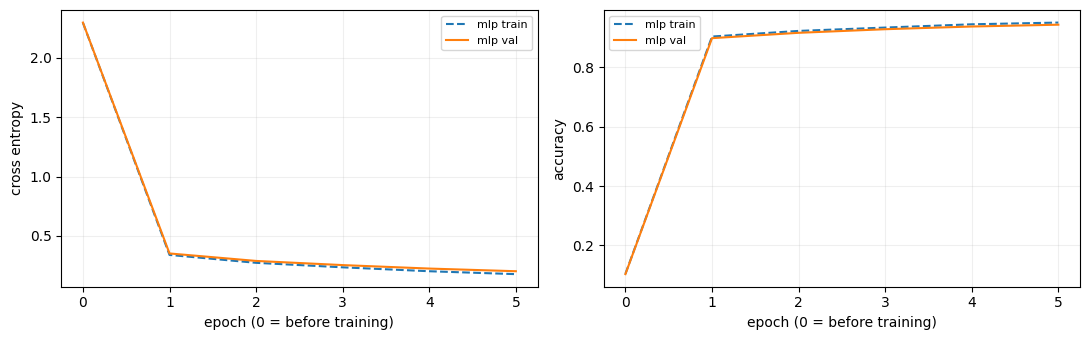

selected MLP epoch: 5


In [13]:
mlp_run = fit("mlp", lr=LR, epochs=EPOCHS, seed=SEED)
assert len(mlp_run["history"]) == EPOCHS + 1
restored_val = evaluate(mlp_run["model"], val_loader, criterion, DEVICE)
assert abs(restored_val["accuracy"] - mlp_run["best_val_accuracy"]) < 1e-12
assert abs(restored_val["loss"] - mlp_run["best_val_loss"]) < 1e-6
_ = plot_history({"mlp": mlp_run["history"]})
print("selected MLP epoch:", mlp_run["best_epoch"])


**参考解释：** 一轮训练包含 $\lceil50000/128ceil=391$ 个 batch，最后一批 80 张；5 轮共 1,955 次参数更新。epoch=0 只记录初始模型，不进行训练，因此历史共有 6 个点。

每轮后分别评估固定模型在训练集和验证集上的表现；online 指标则来自本轮不断变化的参数。选模首先比较验证准确率，再比较验证损失，完全相同保留较早轮次。snapshot 独立复制状态，训练结束恢复所选轮次，所以返回的不一定是最后一轮参数。


## Q6 · 线性基线与模型选择（必做）

**运行前写预测：** 与单隐藏层网络相比，线性分类器的训练速度、参数量、训练和验证准确率会怎样？说明依据。

对照固定划分、预处理、学习率、优化器、batch size、epoch 数和批次顺序。每次独立初始化；不同形状的模型不具有“相同初始参数”。主模型与基线同时改变了非线性与参数量，只能讨论这两种结构在当前训练预算下的表现。

补全结果表，并根据验证集选择最终模型。测试集在这里仍不使用。


**事前预测示例：** MLP 引入非线性，可能改善分类表现，同时具有更多参数。线性模型的单次前向运算更少，但本实验的总耗时也受数据加载和逐轮评估影响，须以实测为准。先提出预测，再查看后面的结果。


linear epoch=0: train loss=2.2912, acc=14.57%; val loss=2.2922, acc=14.22%; elapsed=1.9s


linear epoch=1: train loss=0.4145, acc=88.98%; val loss=0.4223, acc=88.80%; elapsed=5.4s


linear epoch=2: train loss=0.3612, acc=90.14%; val loss=0.3714, acc=89.72%; elapsed=8.8s


linear epoch=3: train loss=0.3395, acc=90.64%; val loss=0.3513, acc=90.27%; elapsed=12.3s


linear epoch=4: train loss=0.3241, acc=91.01%; val loss=0.3384, acc=90.42%; elapsed=15.8s


linear epoch=5: train loss=0.3140, acc=91.34%; val loss=0.3292, acc=90.68%; elapsed=19.2s


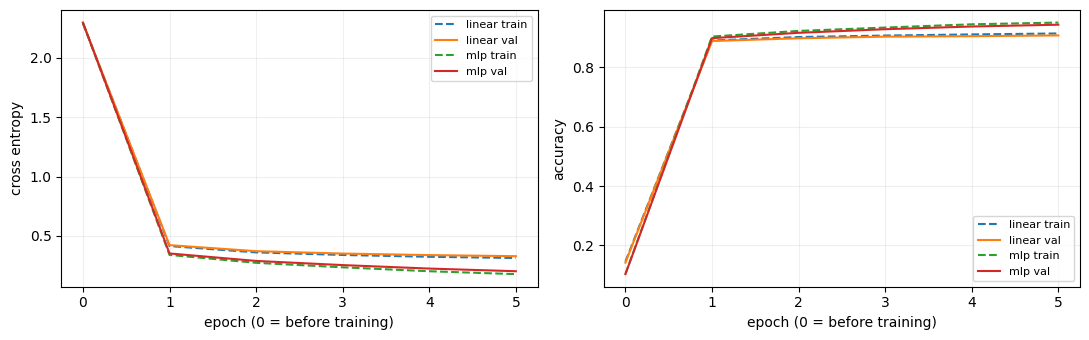

model | parameters | selected epoch | train acc | val acc | val loss | seconds
linear | 7850 | 5 | 0.9134 | 0.9068 | 0.3292 | 19.2
mlp | 101770 | 5 | 0.9500 | 0.9429 | 0.2025 | 20.0
FROZEN choice: mlp epoch: 5


In [14]:
linear_run = fit("linear", lr=LR, epochs=EPOCHS, seed=SEED)
runs = {"linear": linear_run, "mlp": mlp_run}
_ = plot_history({name: run["history"] for name, run in runs.items()})
print("model | parameters | selected epoch | train acc | val acc | val loss | seconds")
for name, run in runs.items():
    best_row = run["history"][run["best_epoch"]]
    print(
        f"{name} | {run['parameters']} | {run['best_epoch']} | "
        f"{best_row['train_accuracy']:.4f} | {run['best_val_accuracy']:.4f} | "
        f"{run['best_val_loss']:.4f} | {run['seconds']:.1f}"
    )
# 同一规则在模型之间选择；完全相同按字典顺序优先选更简单的 linear。
selected_name = max(
    runs,
    key=lambda name: (runs[name]["best_val_accuracy"], -runs[name]["best_val_loss"]),
)
selected_run = runs[selected_name]
final_model = selected_run["model"]
print("FROZEN choice:", selected_name, "epoch:", selected_run["best_epoch"])


**参考对照记录与分析：** 下一个单元根据本次运行结果生成完整表格，并比较验证准确率、参数量和耗时。只使用验证指标选定最终模型，测试数据到 Q7 才使用。


In [15]:
from IPython.display import Markdown, display
rows = ["| 模型 | 参数量 | 选定轮次 | 训练准确率 | 验证准确率 | 验证损失 | 耗时（秒） |",
        "| --- | --- | --- | --- | --- | --- | --- |"]
for name, run in runs.items():
    best_row = run["history"][run["best_epoch"]]
    rows.append(f"| {name} | {run['parameters']:,} | {run['best_epoch']} | "
                f"{best_row['train_accuracy']:.2%} | {run['best_val_accuracy']:.2%} | "
                f"{run['best_val_loss']:.4f} | {run['seconds']:.1f} |")
display(Markdown("\n".join(rows)))
gain = (mlp_run["best_val_accuracy"] - linear_run["best_val_accuracy"]) * 100
ratio = mlp_run["parameters"] / linear_run["parameters"]
print(f"本次 MLP 相对线性模型的验证准确率变化为 {gain:+.2f} 个百分点，参数量约为 {ratio:.2f} 倍。")
print(f"根据预定验证规则选择 {selected_name}，轮次为 {selected_run['best_epoch']}。")
print("该结果仅适用于本次划分、种子与统一训练配置。参数量与非线性同时改变，不能单独归因于激活函数；两种模型也未分别搜索最优超参数。")


| 模型 | 参数量 | 选定轮次 | 训练准确率 | 验证准确率 | 验证损失 | 耗时（秒） |
| --- | --- | --- | --- | --- | --- | --- |
| linear | 7,850 | 5 | 91.34% | 90.68% | 0.3292 | 19.2 |
| mlp | 101,770 | 5 | 95.00% | 94.29% | 0.2025 | 20.0 |

本次 MLP 相对线性模型的验证准确率变化为 +3.61 个百分点，参数量约为 12.96 倍。
根据预定验证规则选择 mlp，轮次为 5。
该结果仅适用于本次划分、种子与统一训练配置。参数量与非线性同时改变，不能单独归因于激活函数；两种模型也未分别搜索最优超参数。


## Q7 · 最终测试与错分样本（必做）

先确认 Q6 已冻结模型、轮次和训练方案，再打开这一部分。只对最终所选模型报告测试指标，不根据测试集再修改学习率或结构。

教师提供按顺序收集前 12 张错分图像的工具。观察哪些数字容易混淆，区分“看到了什么”和“猜测为什么”。p(pred) 是模型给预测类别的 softmax 概率，不是经过校准的正确率保证。

思考：高准确率能否证明模型对任意手写数字都可靠？查看错分图像后提出改进，应该在什么数据上验证？


final model: mlp epoch: 5
train: {'loss': 0.17792011148929596, 'accuracy': 0.95004, 'n': 50000} validation: {'loss': 0.20250536503791808, 'accuracy': 0.9429, 'n': 10000} TEST: {'loss': 0.18643676474094392, 'accuracy': 0.9466, 'n': 10000}
test errors: 534


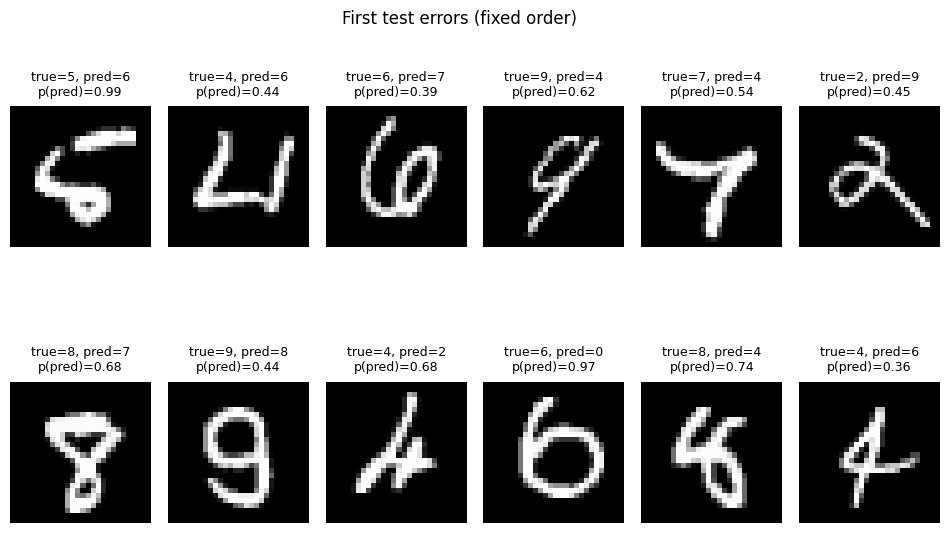

In [16]:
test_set = load_test(download=DOWNLOAD)
assert len(test_set) == 10000
test_loader = make_loader(test_set, BATCH_SIZE)
final_train = evaluate(final_model, train_eval_loader, criterion, DEVICE)
final_val = evaluate(final_model, val_loader, criterion, DEVICE)
final_test = evaluate(final_model, test_loader, criterion, DEVICE)
print("final model:", selected_name, "epoch:", selected_run["best_epoch"])
print("train:", final_train, "validation:", final_val, "TEST:", final_test)
print("test errors:", round((1 - final_test["accuracy"]) * final_test["n"]))
errors = collect_errors(final_model, test_loader, DEVICE, limit=12)
if errors is not None:
    error_images, error_labels, error_preds, error_probs = errors
    # 双行标题需要留出额外行间距；只调整参考版展示，不修改公共工具。
    import matplotlib.pyplot as plt

    count = len(error_images)
    columns = min(6, count)
    rows = math.ceil(count / columns)
    fig, axes = plt.subplots(rows, columns, figsize=(2 * columns, 2.8 * rows), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i >= count:
            continue
        ax.imshow(error_images[i].squeeze(0), cmap="gray", vmin=0, vmax=1)
        ax.set_title(
            f"true={int(error_labels[i])}, pred={int(error_preds[i])}\n"
            f"p(pred)={float(error_probs[i]):.2f}", fontsize=9, pad=8,
        )
    fig.suptitle("First test errors (fixed order)")
    fig.subplots_adjust(top=0.84, bottom=0.03, hspace=0.55, wspace=0.12)
    plt.show()
else:
    print("本次测试没有错分样本；不构造虚假的错误图。")


**参考回答：** 测试指标只描述当前模型在这份 MNIST 测试集上的表现，不能保证任意书写风格、拍照背景或图像位置下都有效。下面展示的是固定顺序中的前 12 个错误，并非全部错误的代表性抽样。

可以观察笔画形状与数字混淆，但“错误由笔画模糊造成”仍是原因假设，需要更多证据。模型给出较高的 p(pred) 也可能判断错误，该概率不是经过校准的正确率保证。查看错分样本后若提出改进，应回到训练／验证流程验证；如果反复利用测试反馈调参，严谨的新评估需要另留独立数据。


In [17]:
print(f"最终模型为 {selected_name}，测试准确率 {final_test['accuracy']:.2%}，"
      f"测试交叉熵 {final_test['loss']:.4f}，共 {final_test['n']} 张图像。")
if errors is not None:
    pairs = [f"{int(truth)}→{int(pred)}" for truth, pred in zip(error_labels, error_preds)]
    print("展示样本的真实类别→预测类别：", "，".join(pairs))
    print("这些是前若干个错误，只支持对已展示图像作具体观察，不能据此断言全体样本中哪种错误最常见。")


最终模型为 mlp，测试准确率 94.66%，测试交叉熵 0.1864，共 10000 张图像。
展示样本的真实类别→预测类别： 5→6，4→6，6→7，9→4，7→4，2→9，8→7，9→8，4→2，6→0，8→4，4→6
这些是前若干个错误，只支持对已展示图像作具体观察，不能据此断言全体样本中哪种错误最常见。


## Q8 · 学习率对照（选做）

固定 MLP、同样初始化、数据划分、批次顺序和 epoch 数，仅改变学习率为 0.01、0.1、0.5。已有 0.1 的结果可直接复用；其他值从新模型开始，不能在 final_model 上继续训练。

把 RUN_EXTENSION 改为 True 前，写下对速度与稳定性的预测。只使用训练／验证指标，不再次查看测试集。若出现非有限值，记录学习率、出错轮次和现象并停止该次实验，不将中断曲线称为收敛。


mlp epoch=0: train loss=2.2961, acc=10.45%; val loss=2.2973, acc=10.35%; elapsed=1.9s


mlp epoch=1: train loss=1.1875, acc=78.00%; val loss=1.1903, acc=78.55%; elapsed=5.5s


mlp epoch=2: train loss=0.6833, acc=84.59%; val loss=0.6875, acc=84.70%; elapsed=9.1s


mlp epoch=3: train loss=0.5302, acc=86.90%; val loss=0.5353, acc=86.99%; elapsed=12.7s


mlp epoch=4: train loss=0.4580, acc=88.07%; val loss=0.4647, acc=88.01%; elapsed=16.3s


mlp epoch=5: train loss=0.4167, acc=88.81%; val loss=0.4240, acc=88.69%; elapsed=19.9s


... (2 outputs left out)

mlp epoch=2: train loss=0.1345, acc=95.82%; val loss=0.1621, acc=95.20%; elapsed=9.1s


mlp epoch=3: train loss=0.1018, acc=97.01%; val loss=0.1375, acc=96.14%; elapsed=12.8s


mlp epoch=4: train loss=0.0682, acc=98.03%; val loss=0.1064, acc=96.84%; elapsed=16.4s


mlp epoch=5: train loss=0.0539, acc=98.48%; val loss=0.0977, acc=97.15%; elapsed=20.0s


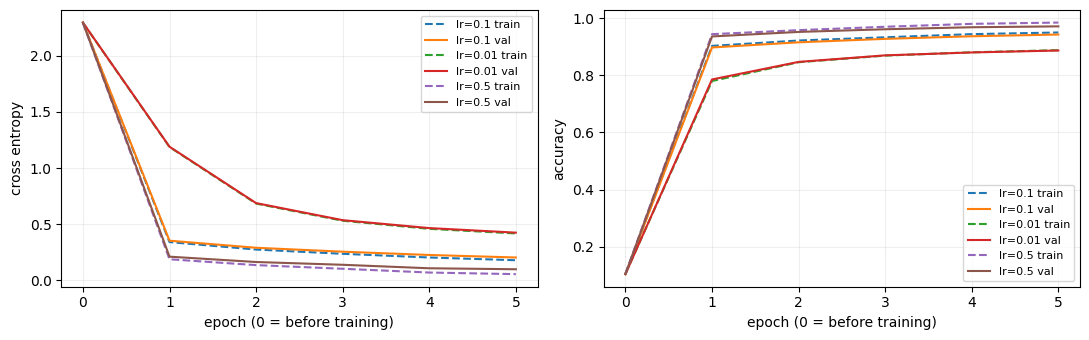

In [18]:
RUN_EXTENSION = True  # 参考版同时运行选做对照，学生仍可跳过。
if RUN_EXTENSION:
    lr_runs = {"lr=0.1": mlp_run}
    for trial_lr in [0.01, 0.5]:
        try:
            lr_runs[f"lr={trial_lr}"] = fit(
                "mlp", lr=trial_lr, epochs=EPOCHS, seed=SEED
            )
        except FloatingPointError as error:
            print("stopped learning rate:", trial_lr, "reason:", error)
    _ = plot_history({name: run["history"] for name, run in lr_runs.items()})
else:
    print("Q8 skipped (optional); Q1–Q7 are unaffected")


**参考解释：** 学习率实验固定模型、初始参数、划分、批次顺序和轮数，只改变学习率。下面根据实际运行的验证结果比较三个设置；没有再次使用测试集，也没有在已经选定的 final_model 上继续训练。


In [19]:
if RUN_EXTENSION:
    print("lr | selected epoch | validation accuracy | validation loss | seconds")
    for label in ["lr=0.01", "lr=0.1", "lr=0.5"]:
        if label not in lr_runs:
            print(label, "本次训练中断，未获得完整结果，不能视为收敛。")
            continue
        run = lr_runs[label]
        print(f"{run['lr']} | {run['best_epoch']} | {run['best_val_accuracy']:.2%} | "
              f"{run['best_val_loss']:.4f} | {run['seconds']:.1f}")
    best_lr_label = max(lr_runs, key=lambda k: (lr_runs[k]["best_val_accuracy"], -lr_runs[k]["best_val_loss"]))
    print("本次完整返回结果中验证表现最好的设置：", best_lr_label)
    print("小学习率可能在当前轮数内进展较慢；较大学习率可能更快，也可能振荡。结论结合曲线，并限定于本任务、初始化与训练预算。")


lr | selected epoch | validation accuracy | validation loss | seconds
0.01 | 5 | 88.69% | 0.4240 | 19.9
0.1 | 5 | 94.29% | 0.2025 | 20.0
0.5 | 5 | 97.15% | 0.0977 | 20.0
本次完整返回结果中验证表现最好的设置： lr=0.5
小学习率可能在当前轮数内进展较慢；较大学习率可能更快，也可能振荡。结论结合曲线，并限定于本任务、初始化与训练预算。


## 参考资料

本实验的题目、检查和文字解释为课程自拟，参考下列公开材料的教学结构：

- [d2l 3.5：图像分类数据集](https://zh.d2l.ai/chapter_linear-networks/image-classification-dataset.html)（原书使用 Fashion-MNIST，本实验采用 MNIST）。
- [d2l 3.7：softmax 回归的简洁实现](https://zh.d2l.ai/chapter_linear-networks/softmax-regression-concise.html)。
- [d2l 4.3：多层感知机的简洁实现](https://zh.d2l.ai/chapter_multilayer-perceptrons/mlp-concise.html)。
- [PyTorch：优化模型参数](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html)。
- [torchvision：MNIST](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html)。

本实验另设验证集，训练与评估代码显式展开，不依赖 d2l 的训练封装。
